   todas_na_rua    so_2020_2025 homens_mulheres 
         993605          911648          661555 


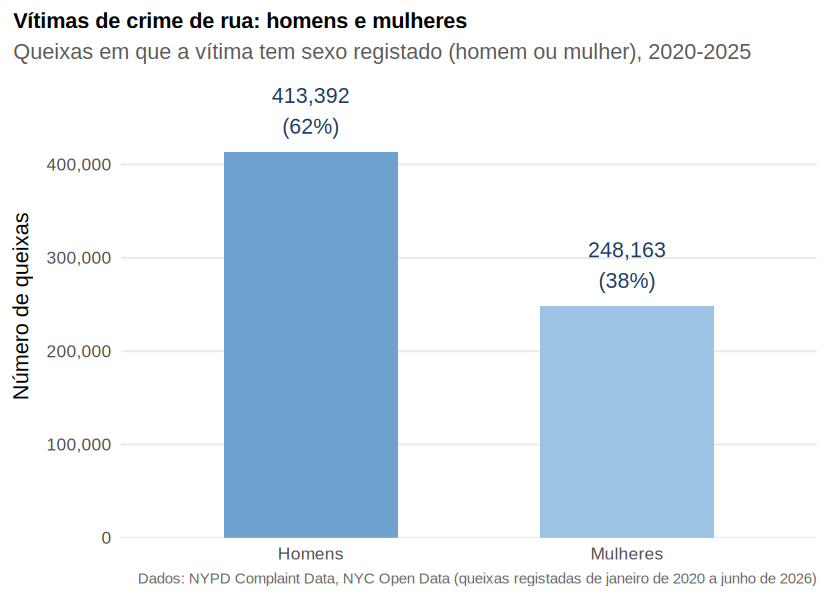

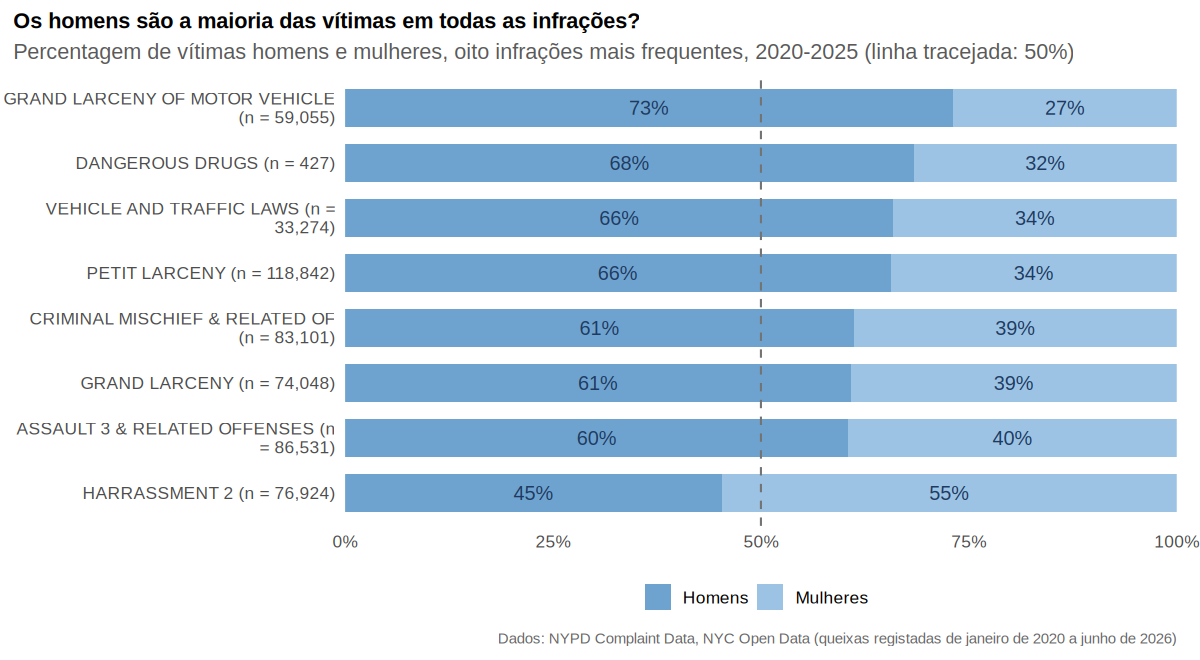

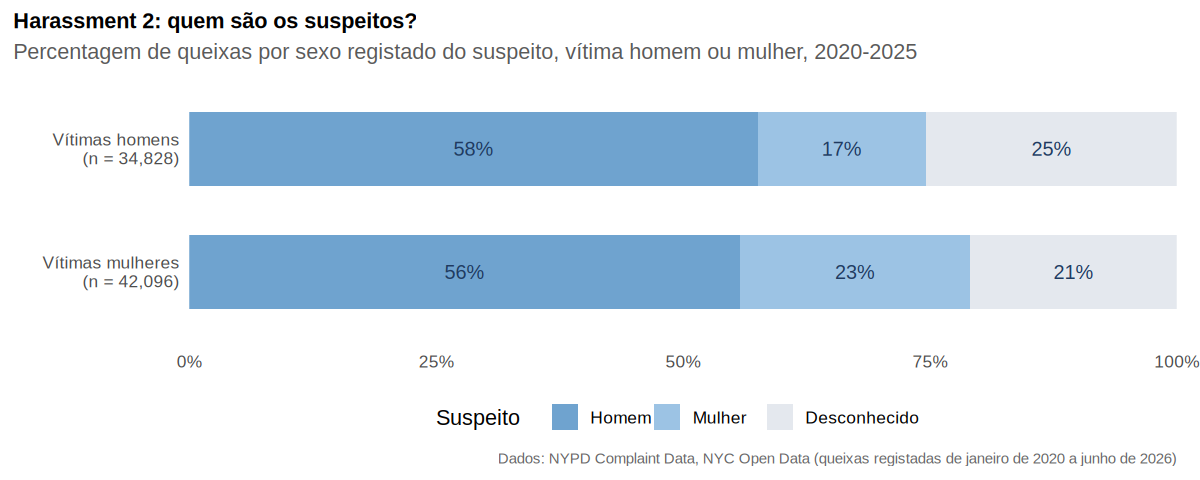

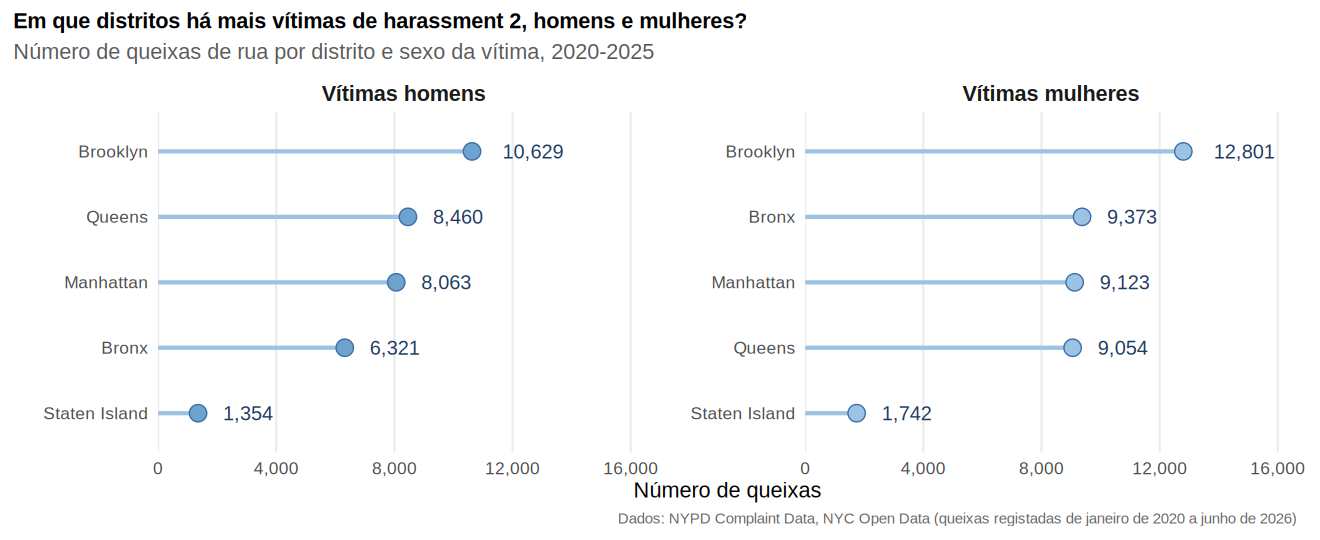

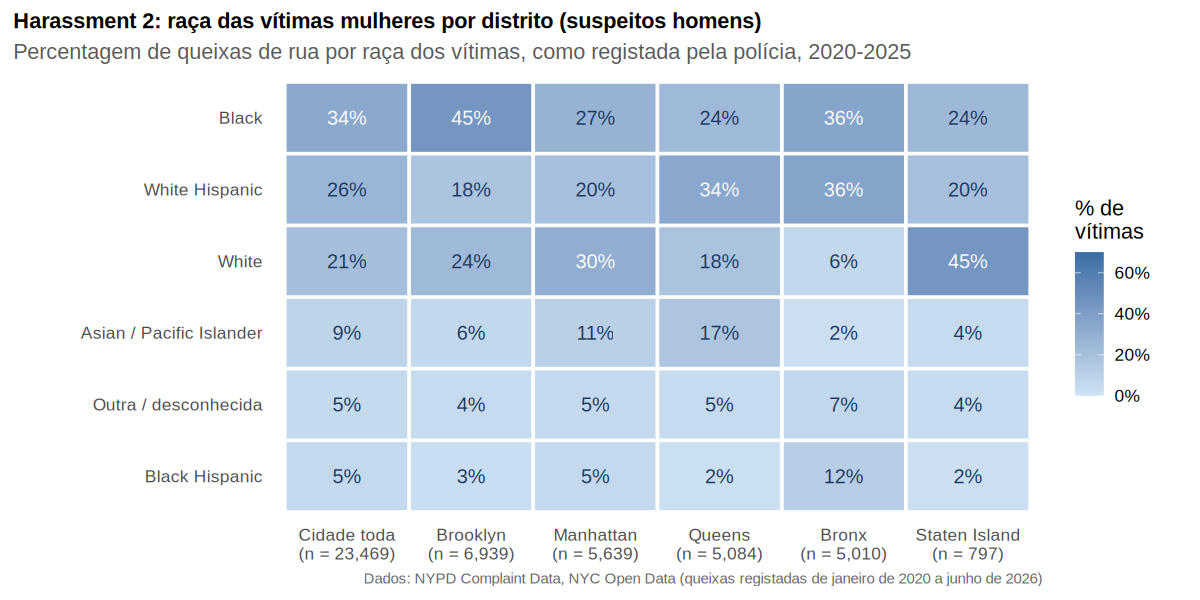

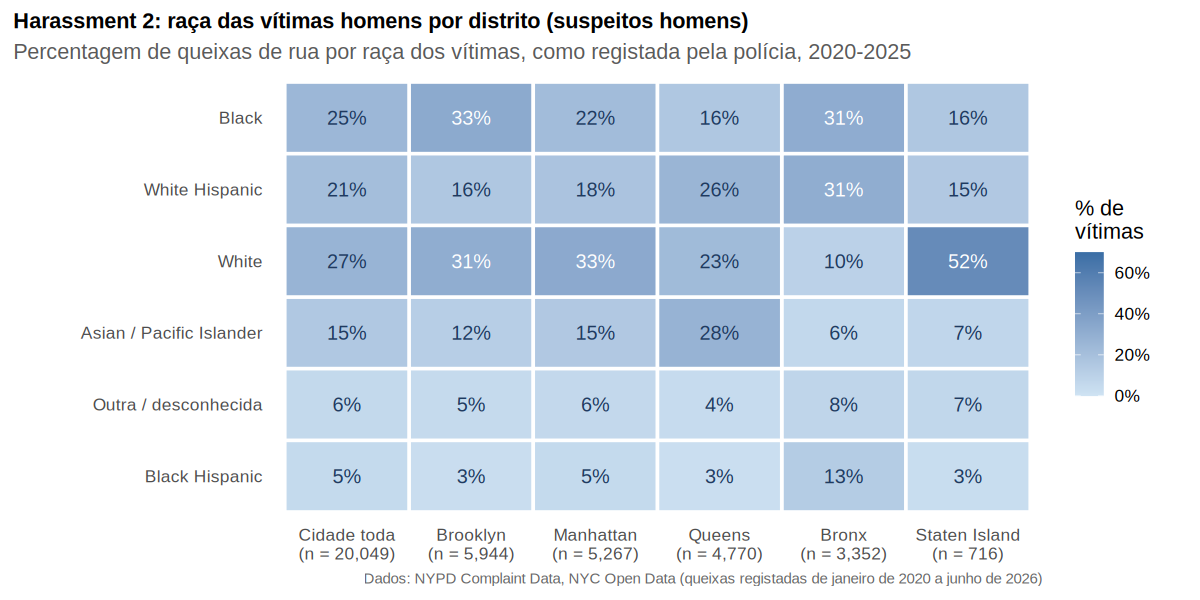

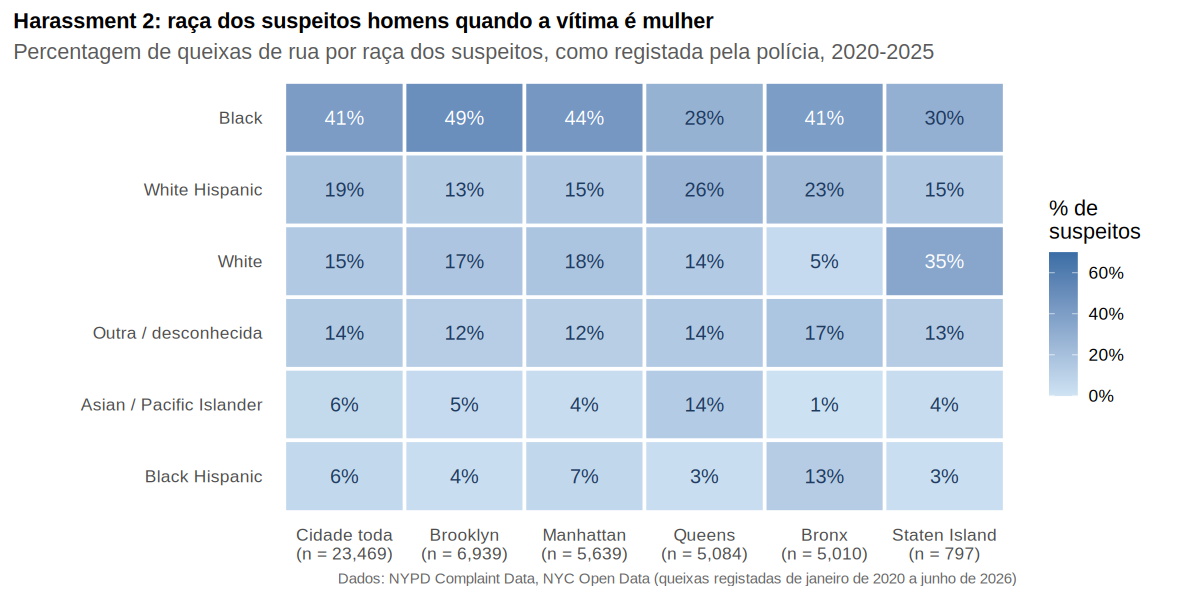

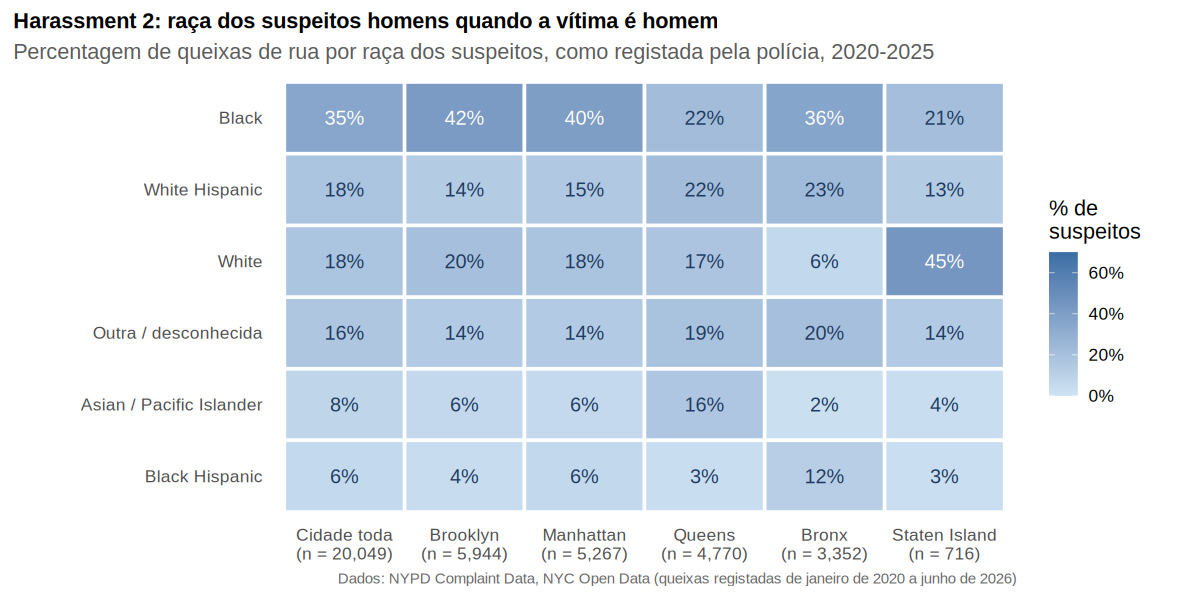

In [2]:
# PERGUNTA CENTRAL: Quem são as vítimas de crime de rua em Nova Iorque, e isto muda ao longo do tempo e pela cidade?

# HIPÓTESE INICIAL (DESCARTADA)
# Os crimes de rua estão distribuídos de forma igual entre grupos de vítimas e locais.
# Descartada porque a pergunta fica respondida por qualquer resultado
# e, sem dados de população, as diferenças de contagem não se podem interpretar
# como maior ou menor afetação.

# OBSERVAÇÃO QUE ORIGINOU A NOVA HIPÓTESE
# Nos gráficos exploratórios, cerca de 6 em cada 10 vítimas de crime de rua são homens.

# NOVA HIPÓTESE (a verificar nos dados)
# Os homens são a maioria das vítimas em todas as infrações de rua.

# ==============================================================================
# CORES (tudo em tons de azul pastel; definidas uma vez e usadas em todos os gráficos)
# ==============================================================================
cor_claro    <- "#CFE3F3"   # azul mais claro: valores baixos nos mapas de calor
cor_medio    <- "#9CC3E4"   # azul pastel: mulheres
cor_azul     <- "#6FA3CF"   # azul principal: homens
cor_destaque <- "#3A6EA5"   # azul escuro: destaques e valores altos
cor_cinza2   <- "#E4E8EE"   # cinza azulado muito claro: desconhecido
cor_ref      <- "grey45"    # linhas de referência (50%)
cor_texto    <- "#1F3A5F"   # cor dos números dentro dos gráficos

# ==============================================================================
# PREPARAÇÃO: pacotes, dados e tabelas comuns a todos os gráficos
# ==============================================================================
library(dplyr)       # trabalhar com tabelas: filtrar, contar, agrupar
library(ggplot2)     # desenhar os gráficos
library(scales)      # formatar números (milhares) e percentagens
library(lubridate)   # trabalhar com datas

# ler o ficheiro de dados do projeto
# no Colab: o ficheiro está na pasta de ficheiros; no computador: está na pasta data/ do projeto
ficheiro_dados <- if (file.exists("nypd_2020_2026.rds")) "nypd_2020_2026.rds" else "../data/nypd_2020_2026.rds"
nypd <- as.data.frame(readRDS(ficheiro_dados))

# pasta onde se gravam as figuras: fig/ do projeto no computador, pasta atual no Colab
pasta_fig <- if (dir.exists("../fig")) "../fig/" else ""

# texto da fonte, que aparece por baixo de todos os gráficos
fonte <- "Dados: NYPD Complaint Data, NYC Open Data (queixas registadas de janeiro de 2020 a junho de 2026)"

# estilo comum a todos os gráficos (letra, títulos, margens)
tema_vd <- theme_minimal(base_size = 13) +
  theme(plot.title.position = "plot",
        plot.title    = element_text(face = "bold", size = 13),
        plot.subtitle = element_text(colour = "grey35"),
        plot.caption  = element_text(colour = "grey40", size = 9),
        panel.grid.minor = element_blank(),
        plot.margin = margin(8, 14, 8, 8))

# período do estudo: só anos completos (2026 está incompleto)
study_start <- as.Date("2020-01-01")
study_end   <- as.Date("2025-12-31")

# só queixas ocorridas na rua
street <- nypd %>% filter(prem_typ_desc == "STREET")

# base comum: queixas de rua dentro do período de estudo
st_base <- street %>%
  mutate(event_date  = as.Date(cmplnt_fr_dt),    # data em que o incidente aconteceu
         report_date = as.Date(rpt_dt)) %>%      # data em que foi comunicado à polícia
  filter(event_date >= study_start, event_date <= study_end,          # só 2020-2025
         is.na(report_date) | event_date <= report_date)              # o incidente não pode ser depois da queixa

# base das vítimas: só pessoas com sexo conhecido (F = mulher, M = homem)
fm <- st_base %>%
  filter(vic_sex %in% c("F", "M")) %>%
  mutate(man = vic_sex == "M")                   # nova coluna: verdadeiro se a vítima é homem

# controlo: porque é que as barras do gráfico 1 somam menos do que o total de queixas de rua?
print(c(todas_na_rua    = nrow(street),          # inclui 2026
        so_2020_2025    = nrow(st_base),         # depois de retirar 2026 e datas incoerentes
        homens_mulheres = nrow(fm)))             # depois de retirar organizações, Estado e desconhecidos

# ==============================================================================
# GRÁFICO 1. Quantos homens e quantas mulheres são vítimas de crime de rua?
# ==============================================================================
# Tipo: barras, porque são só duas categorias comparadas pelo mesmo número (queixas).

# tabela: nº de queixas e percentagem por sexo da vítima
sex_total <- fm %>%
  count(vic_sex) %>%                                                  # conta as queixas de cada sexo
  mutate(sex   = factor(if_else(vic_sex == "M", "Homens", "Mulheres"),
                        levels = c("Homens", "Mulheres")),            # nome em português e ordem das barras
         share = n / sum(n))                                          # percentagem de cada sexo

options(repr.plot.width = 7, repr.plot.height = 5)                    # tamanho do gráfico no Colab

p_sex_total <- ggplot(sex_total, aes(x = sex, y = n, fill = sex)) +   # x = sexo, y = nº de queixas, cor = sexo
  geom_col(width = 0.55, show.legend = FALSE) +                       # desenha as barras
  geom_text(aes(label = paste0(comma(n), "\n(", percent(share, accuracy = 1), ")")),
            vjust = -0.4, size = 4.5, colour = cor_texto) +           # escreve o número e a % em cima de cada barra
  scale_fill_manual(values = c("Homens" = cor_azul, "Mulheres" = cor_medio)) +    # cor de cada sexo
  scale_y_continuous(labels = comma, expand = expansion(mult = c(0, 0.2))) +      # eixo y a começar em 0
  labs(title = "Vítimas de crime de rua: homens e mulheres",
       subtitle = "Queixas em que a vítima tem sexo registado (homem ou mulher), 2020-2025",
       x = NULL, y = "Número de queixas", caption = fonte) +
  tema_vd + theme(panel.grid.major.x = element_blank())
print(p_sex_total)                                                    # mostra o gráfico
ggsave(paste0(pasta_fig, "figura_rua_1_sexo_vitimas.png"), p_sex_total, width = 7, height = 5, dpi = 300)   # guarda a imagem

# ==============================================================================
# GRÁFICO 2. Os homens são a maioria em todas as infrações?
# ==============================================================================
# Tipo: barras empilhadas a 100%, porque queremos ver a parte de cada sexo dentro de cada infração.

# as 8 infrações com mais queixas
top8 <- st_base %>%
  filter(!is.na(ofns_desc)) %>%
  count(ofns_desc, sort = TRUE) %>%                                   # conta as queixas por infração, da maior para a menor
  slice_head(n = 8) %>%                                               # fica com as 8 primeiras
  pull(ofns_desc)                                                     # guarda só os nomes

# tabela: % de vítimas homens e mulheres dentro de cada infração
sex_off <- fm %>%
  filter(ofns_desc %in% top8) %>%
  mutate(sex = if_else(man, "Homens", "Mulheres")) %>%
  count(ofns_desc, sex) %>%                                           # queixas por infração e sexo
  group_by(ofns_desc) %>%                                             # as contas seguintes são feitas dentro de cada infração
  mutate(total     = sum(n),                                          # total de queixas da infração
         share     = n / total,                                       # percentagem de cada sexo
         men_share = sum(n[sex == "Homens"]) / total,                 # % de homens (só para ordenar as barras)
         label     = paste0(ofns_desc, " (n = ", comma(total), ")")) %>%   # nome da infração com o total
  ungroup() %>%
  mutate(sex = factor(sex, levels = c("Mulheres", "Homens")))

options(repr.plot.width = 10, repr.plot.height = 5.5)

p_sex_off <- ggplot(sex_off, aes(x = share, y = reorder(label, men_share), fill = sex)) +
  geom_col(width = 0.7) +                                             # barras empilhadas
  geom_vline(xintercept = 0.5, linetype = "dashed", colour = cor_ref) +   # linha dos 50%
  geom_text(aes(label = percent(share, accuracy = 1)),
            position = position_stack(vjust = 0.5), size = 4.2, colour = cor_texto) +   # % dentro de cada parte
  scale_x_continuous(labels = percent, expand = c(0, 0)) +
  scale_y_discrete(labels = label_wrap(32)) +                         # parte nomes compridos em duas linhas
  scale_fill_manual(values = c("Homens" = cor_azul, "Mulheres" = cor_medio), breaks = c("Homens", "Mulheres")) +
  labs(title = "Os homens são a maioria das vítimas em todas as infrações?",
       subtitle = "Percentagem de vítimas homens e mulheres, oito infrações mais frequentes, 2020-2025 (linha tracejada: 50%)",
       x = NULL, y = NULL, fill = NULL, caption = fonte) +
  tema_vd + theme(panel.grid = element_blank(), legend.position = "bottom")
print(p_sex_off)
ggsave(paste0(pasta_fig, "figura_rua_2_infracoes.png"), p_sex_off, width = 9, height = 5.5, dpi = 300)

# ==============================================================================
# GRÁFICO 3. Harassment 2: quem são os suspeitos quando a vítima é homem e quando é mulher?
# ==============================================================================
# Tipo: barras empilhadas a 100% (parte de cada sexo do suspeito dentro de cada grupo de vítimas).
# "Desconhecido" = o suspeito não foi identificado ou descrito; não quer dizer que não houve suspeito.

sus_sum <- fm %>%
  filter(grepl("HARRASSMENT 2", ofns_desc)) %>%                       # só harassment 2 (está escrito assim nos dados)
  mutate(victim  = if_else(man, "Vítimas homens", "Vítimas mulheres"),
         suspect = case_when(susp_sex == "M" ~ "Homem",
                             susp_sex == "F" ~ "Mulher",
                             TRUE            ~ "Desconhecido")) %>%   # qualquer outro valor = desconhecido
  count(victim, suspect) %>%                                          # queixas por sexo da vítima e do suspeito
  group_by(victim) %>%
  mutate(total = sum(n),                                              # total de cada grupo de vítimas
         share = n / total) %>%                                       # percentagem de cada tipo de suspeito
  ungroup() %>%
  mutate(lab = paste0(victim, "\n(n = ", comma(total), ")"))          # nome da barra com o total

# ordem das barras: homens em cima, mulheres em baixo
ordem_lab <- sus_sum %>% distinct(victim, lab) %>% arrange(desc(victim)) %>% pull(lab)

options(repr.plot.width = 10, repr.plot.height = 4)

p_suspect <- ggplot(sus_sum, aes(x = share, y = factor(lab, levels = ordem_lab),
                                 fill = factor(suspect, levels = c("Desconhecido", "Mulher", "Homem")))) +
  geom_col(width = 0.6) +
  geom_text(aes(label = ifelse(share >= 0.04, percent(share, accuracy = 1), "")),   # só escreve a % se for maior que 4%
            position = position_stack(vjust = 0.5), size = 4.2, colour = cor_texto) +
  scale_x_continuous(labels = percent, expand = c(0, 0)) +
  scale_fill_manual(values = c("Homem" = cor_azul, "Mulher" = cor_medio, "Desconhecido" = cor_cinza2),
                    breaks = c("Homem", "Mulher", "Desconhecido")) +
  labs(title = "Harassment 2: quem são os suspeitos?",
       subtitle = "Percentagem de queixas por sexo registado do suspeito, vítima homem ou mulher, 2020-2025",
       x = NULL, y = NULL, fill = "Suspeito", caption = fonte) +
  tema_vd + theme(panel.grid = element_blank(), legend.position = "bottom")
print(p_suspect)
ggsave(paste0(pasta_fig, "figura_rua_3_suspeitos_harassment2.png"), p_suspect, width = 9, height = 4, dpi = 300)

# ==============================================================================
# GRÁFICO 4. Harassment 2: em que distritos há mais vítimas homens e mais vítimas mulheres?
# ==============================================================================
# Tipo: lollipop (linha com um ponto na ponta), um painel por sexo, distritos ordenados do menor para o maior.
# São contagens: mostram onde há mais queixas, não onde há maior risco (não temos dados de população).

nomes_sex <- c("Vítimas homens", "Vítimas mulheres")

har_boro <- fm %>%
  filter(grepl("HARRASSMENT 2", ofns_desc), boro_nm != "(null)") %>%  # só harassment 2, com distrito conhecido
  mutate(sex  = factor(if_else(man, nomes_sex[1], nomes_sex[2]), levels = nomes_sex),
         boro = tools::toTitleCase(tolower(boro_nm))) %>%             # nome do distrito com maiúscula só na 1.ª letra
  count(sex, boro, name = "victims") %>%                              # queixas por sexo da vítima e distrito
  arrange(sex, victims) %>%
  mutate(key = factor(paste(sex, boro, sep = "|"), levels = unique(paste(sex, boro, sep = "|"))))   # ordem dos distritos em cada painel

options(repr.plot.width = 11, repr.plot.height = 4.5)

p_har_boro <- ggplot(har_boro, aes(x = victims, y = key)) +
  geom_segment(aes(x = 0, xend = victims, yend = key), colour = cor_medio, linewidth = 1.2) +   # a linha
  geom_point(aes(fill = sex), shape = 21, size = 4.5, colour = cor_destaque) +                   # o ponto na ponta
  geom_text(aes(label = comma(victims)), hjust = -0.5, size = 4.2, colour = cor_texto) +         # o número ao lado
  facet_wrap(~sex, scales = "free_y") +                                                          # um painel para cada sexo
  scale_y_discrete(labels = function(x) sub("^.*\\|", "", x)) +                                  # tira o prefixo do sexo do nome do distrito
  scale_x_continuous(labels = comma, limits = c(0, NA), expand = expansion(mult = c(0, 0.3))) +  # espaço para o número não ser cortado
  scale_fill_manual(values = c("Vítimas homens" = cor_azul, "Vítimas mulheres" = cor_medio), guide = "none") +
  labs(title = "Em que distritos há mais vítimas de harassment 2, homens e mulheres?",
       subtitle = "Número de queixas de rua por distrito e sexo da vítima, 2020-2025",
       x = "Número de queixas", y = NULL, caption = fonte) +
  tema_vd + theme(panel.grid.major.y = element_blank(), strip.text = element_text(face = "bold", size = 13))
print(p_har_boro)
ggsave(paste0(pasta_fig, "figura_rua_4_distritos_harassment2.png"), p_har_boro, width = 10, height = 4.5, dpi = 300)

# ==============================================================================
# GRÁFICOS 5 A 8. Harassment 2 com suspeito homem: raça por distrito (opcional)
# ==============================================================================
# Tipo: mapa de calor (duas dimensões: raça x distrito). A raça é a registada pela polícia.
# Só entram queixas com suspeito homem e com distrito. Cada coluna soma 100% (% dentro de cada distrito).
# 5 e 6: raça das VÍTIMAS (mulheres / homens). 7 e 8: raça dos SUSPEITOS (vítimas mulheres / homens).
# Se o grupo decidir não usar estes gráficos, apagar daqui até ao título "O QUE O MAYOR E A NYPD PODEM FAZER".

racas <- c("BLACK", "WHITE HISPANIC", "WHITE", "ASIAN / PACIFIC ISLANDER", "BLACK HISPANIC")   # grupos principais (como estão nos dados)

har_raca <- fm %>%
  filter(grepl("HARRASSMENT 2", ofns_desc),   # só harassment 2
         susp_sex == "M",                     # suspeito homem
         boro_nm != "(null)")                 # com distrito conhecido

# função que desenha um mapa de calor
#   homem = TRUE (vítimas homens) ou FALSE (vítimas mulheres)
#   col   = "vic_race" (raça da vítima) ou "susp_race" (raça do suspeito)
#   quem  = "vítimas" ou "suspeitos" (só para a legenda e o subtítulo)
raca_plot <- function(homem, titulo, col = "vic_race", quem = "vítimas") {
  # junta as raças pequenas em "Outra / desconhecida"
  cl <- function(d) d %>% mutate(raca = if_else(.data[[col]] %in% racas,
                                                tools::toTitleCase(tolower(.data[[col]])), "Outra / desconhecida"))

  ordem_y <- cl(har_raca) %>% count(raca) %>% arrange(n) %>% pull(raca)   # mesma ordem das linhas em todos os gráficos

  d <- cl(har_raca %>% filter(man == homem))
  race_boro <- bind_rows(
    d %>% mutate(zona = tools::toTitleCase(tolower(boro_nm))),   # um grupo por distrito
    d %>% mutate(zona = "Cidade toda")                            # total de Nova Iorque
  ) %>%
    count(zona, raca) %>%
    group_by(zona) %>%
    mutate(total = sum(n), share = n / total) %>%                 # % de cada raça dentro do distrito
    ungroup() %>%
    mutate(zona_lab = paste0(zona, "\n(n = ", comma(total), ")"))

  ordem_x <- race_boro %>% distinct(zona, zona_lab, total) %>%
    mutate(ord = if_else(zona == "Cidade toda", Inf, total)) %>% arrange(desc(ord)) %>% pull(zona_lab)   # "Cidade toda" primeiro

  ggplot(race_boro, aes(x = factor(zona_lab, levels = ordem_x),
                        y = factor(raca, levels = ordem_y), fill = share)) +
    geom_tile(colour = "white", linewidth = 1) +                                       # os quadrados do mapa de calor
    geom_text(aes(label = percent(share, accuracy = 1), colour = share > 0.3), size = 4.2) +   # % dentro de cada quadrado
    scale_colour_manual(values = c("TRUE" = "white", "FALSE" = cor_texto), guide = "none") +   # texto branco nos quadrados escuros
    scale_fill_gradient(low = cor_claro, high = cor_destaque, labels = percent,
                        limits = c(0, 0.7), name = paste0("% de\n", quem)) +           # mesma escala de cor em todos
    labs(title = titulo,
         subtitle = paste0("Percentagem de queixas de rua por raça dos ", quem, ", como registada pela polícia, 2020-2025"),
         x = NULL, y = NULL, caption = fonte) +
    tema_vd + theme(panel.grid = element_blank())
}

options(repr.plot.width = 10, repr.plot.height = 5)

# gráfico 5: raça das vítimas, vítimas mulheres
p_raca_mulher <- raca_plot(FALSE, "Harassment 2: raça das vítimas mulheres por distrito (suspeitos homens)")
print(p_raca_mulher)
ggsave(paste0(pasta_fig, "figura_rua_5_raca_vitimas_mulheres.png"), p_raca_mulher, width = 10, height = 5, dpi = 300)

# gráfico 6: raça das vítimas, vítimas homens
p_raca_homem <- raca_plot(TRUE, "Harassment 2: raça das vítimas homens por distrito (suspeitos homens)")
print(p_raca_homem)
ggsave(paste0(pasta_fig, "figura_rua_6_raca_vitimas_homens.png"), p_raca_homem, width = 10, height = 5, dpi = 300)

# gráfico 7: raça dos suspeitos, vítimas mulheres
p_raca_susp_mulher <- raca_plot(FALSE, "Harassment 2: raça dos suspeitos homens quando a vítima é mulher",
                                col = "susp_race", quem = "suspeitos")
print(p_raca_susp_mulher)
ggsave(paste0(pasta_fig, "figura_rua_7_raca_suspeitos_vitimas_mulheres.png"), p_raca_susp_mulher, width = 10, height = 5, dpi = 300)

# gráfico 8: raça dos suspeitos, vítimas homens
p_raca_susp_homem <- raca_plot(TRUE, "Harassment 2: raça dos suspeitos homens quando a vítima é homem",
                               col = "susp_race", quem = "suspeitos")
print(p_raca_susp_homem)
ggsave(paste0(pasta_fig, "figura_rua_8_raca_suspeitos_vitimas_homens.png"), p_raca_susp_homem, width = 10, height = 5, dpi = 300)

# ==============================================================================
# O QUE O MAYOR E A NYPD PODEM FAZER (sugestões do grupo, não resultados dos dados)
# ==============================================================================
# - Em harassment 2 as vítimas dividem-se quase por igual entre mulheres e homens (cerca de 55% / 45%)
#   e os suspeitos são sobretudo homens nos dois casos. Por isso, as ações de prevenção e de
#   sensibilização não devem ser dirigidas só a mulheres.
# - Em cerca de 1 em cada 4 queixas o sexo do suspeito não está registado (25% e 21%). A NYPD pode
#   melhorar o registo da descrição do suspeito para que estas análises sejam mais fiáveis.
# - O Brooklyn (gráfico 4) é o distrito com mais queixas de harassment 2;
#   o patrulhamento pode ser reforçado onde há mais queixas, tendo em conta que são contagens e que
#   sem dados de população não se fala de risco.

# ==============================================================================
# CONCLUSÃO
# ==============================================================================
# RESULTADO DA HIPÓTESE: rejeitada, porque não se verifica em todas as infrações.
# - Gráfico 1: entre as vítimas com sexo registado, cerca de 6 em cada 10 são homens.
# - Gráfico 2: os homens são a maioria em 7 das 8 infrações principais. Em harassment 2 as mulheres
#   são a maioria das vítimas (55%).
# - Gráfico 3: em harassment 2 os suspeitos são homens em 58% das queixas com vítima homem e em 56%
#   das queixas com vítima mulher. Mesmo contando o suspeito desconhecido (25% e 21%) como "não homem",
#   a maioria mantém-se.
# - Gráfico 4: o Brooklyn é o distrito com mais queixas de harassment 2 dos dois sexos (contagens, não risco).
# - Gráficos 5 a 8: raça das vítimas e dos suspeitos (registada pela polícia) em harassment 2 com
#   suspeito homem, por distrito.
# Limitações: contamos queixas e não pessoas; sem dados de população não falamos de risco;
# só entram vítimas com sexo F ou M; o ficheiro não regista causas, por isso não explicamos
# o porquê de os suspeitos serem sobretudo homens.